# Review 2 — Classification Comparison: All 10 Algorithms

Run all five Part A and five Part B classifier notebooks first. This notebook normalizes their result-file schemas and consolidates all ten models into one table, then compares Accuracy, Precision, Recall, weighted F1, and ROC-AUC. Confusion matrices are displayed in the individual algorithm notebooks.


## 1. Imports and result paths

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "bank-full.csv").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not locate project root containing data/bank-full.csv")
    ROOT = ROOT.parent
RESULTS = ROOT / "results" / "classification"
FIGURES = ROOT / "figures" / "classification"
MODELS = ROOT / "models" / "classification"
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("Results folder:", RESULTS)


Project root: /home/manohar/Downloads/ML_Capstone_Final_UI/Review2
Results folder: /home/manohar/Downloads/ML_Capstone_Final_UI/Review2/results/classification


## 2. Load results and build the consolidated table

In [2]:
required = {"accuracy", "precision", "recall", "weighted_f1", "roc_auc"}
frames = []
for path in sorted(RESULTS.glob("*.csv")):
    if "tuning" in path.name.lower() or path.name == "classification_comparison_all_10.csv":
        continue
    try:
        d = pd.read_csv(path)
        # Part A files use `model`; Part B files use `algorithm`.
        if "algorithm" not in d.columns and "model" in d.columns:
            d = d.rename(columns={"model": "algorithm"})
        if {"algorithm", *required}.issubset(d.columns):
            frames.append(d[["algorithm", "accuracy", "precision", "recall", "weighted_f1", "roc_auc"]])
        else:
            print("Skipped (unexpected columns):", path.name, list(d.columns))
    except Exception as exc:
        print("Skipped:", path.name, exc)

if not frames:
    raise FileNotFoundError("No compatible classification metric CSVs found in " + str(RESULTS))
comparison = pd.concat(frames, ignore_index=True)
comparison["algorithm"] = comparison["algorithm"].astype(str).str.strip()
# Keep the latest file row per algorithm; filenames are sorted for reproducible behavior.
comparison = comparison.drop_duplicates("algorithm", keep="last")
expected = [
    "Logistic Regression", "K-Nearest Neighbors", "Gaussian Naive Bayes",
    "Decision Tree Classifier", "Support Vector Classifier (SVC)",
    "Random Forest", "AdaBoost", "Gradient Boosting",
    "Bagging (Decision Tree)", "MLP Neural Network"
]
# Accommodate small label differences between notebook versions.
aliases = {"Decision Tree": "Decision Tree Classifier", "SVC (linear)": "Support Vector Classifier (SVC)", "Support Vector Classifier": "Support Vector Classifier (SVC)"}
comparison["algorithm"] = comparison["algorithm"].replace(aliases)
comparison = comparison.drop_duplicates("algorithm", keep="last")
missing = [name for name in expected if name not in set(comparison["algorithm"])]
extra = [name for name in comparison["algorithm"] if name not in expected]
comparison = comparison.sort_values("weighted_f1", ascending=False).reset_index(drop=True)
display(comparison.round(4))
comparison.to_csv(RESULTS / "classification_comparison_all_10.csv", index=False)
print("Number of algorithms included:", comparison["algorithm"].nunique())
print("Missing required algorithms:", missing)
if extra:
    print("Additional/unrecognized algorithm labels:", extra)
if missing:
    print("Run the missing algorithm notebooks, then rerun this comparison.")


,algorithm,accuracy,precision,recall,weighted_f1,roc_auc
0,MLP Neural Network,0.9050,0.6294,0.4575,0.8983,0.9146
1,Bagging (Decision Tree),0.9030,0.6186,0.4461,0.8960,0.9127
2,Gradient Boosting,0.9059,0.6610,0.4017,0.8956,0.9195
3,Decision Tree Classifier,0.9011,0.6367,0.3611,0.8889,0.8529
4,Random Forest,0.9045,0.6988,0.3223,0.8885,0.9219
5,Logistic Regression,0.8991,0.6347,0.3251,0.8845,0.9006
6,K-Nearest Neighbors,0.8980,0.6255,0.3204,0.8832,0.8341
7,AdaBoost,0.8952,0.6545,0.2202,0.8714,0.8919
8,Support Vector Classifier (SVC),0.8932,0.6503,0.1881,0.8661,0.8926
9,Gaussian Naive Bayes,0.8519,0.3946,0.4972,0.8591,0.8021


Number of algorithms included: 10
Missing required algorithms: []


## 3. Compare all metrics visually

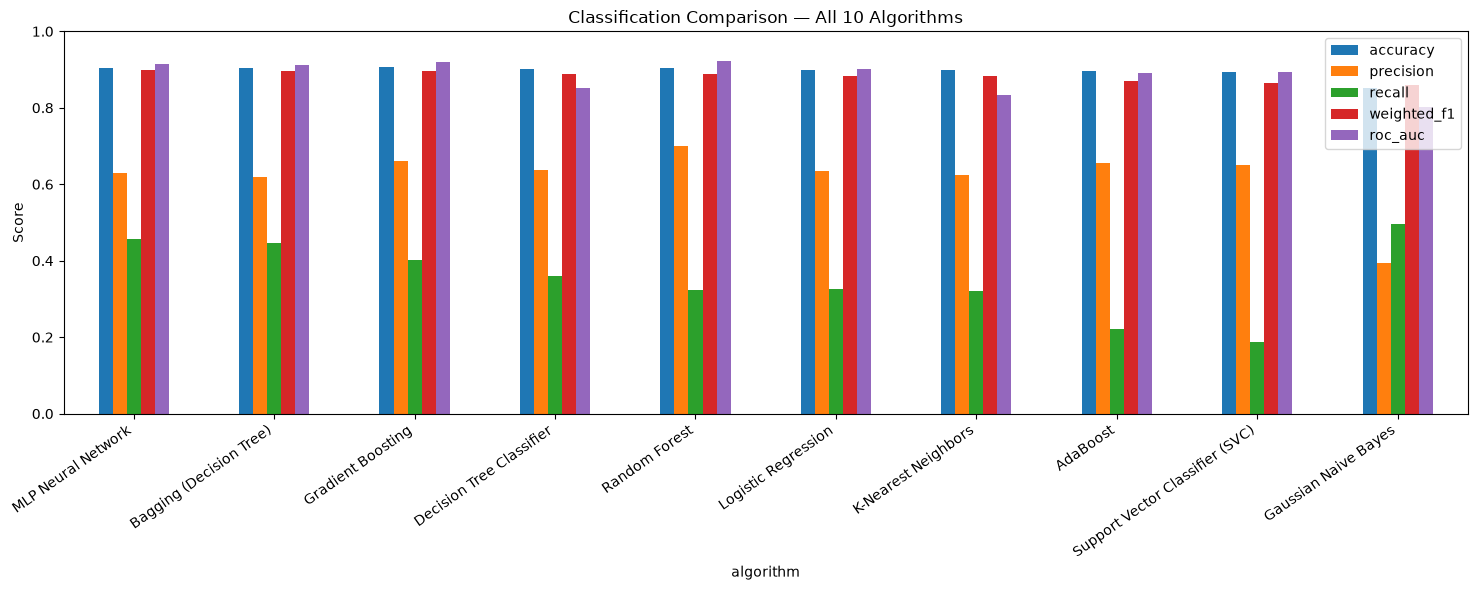

In [3]:
if comparison["algorithm"].nunique() == 0:
    raise ValueError("No classifier metrics were loaded. Run the classification notebooks first.")
ax = comparison.set_index("algorithm")[["accuracy", "precision", "recall", "weighted_f1", "roc_auc"]].plot(kind="bar", figsize=(15, 6))
ax.set_title("Classification Comparison — All 10 Algorithms")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIGURES / "classification_all_10_metric_comparison.png", dpi=150)
plt.show()


## 4. Best models by weighted F1 and ROC-AUC

In [4]:
display(comparison.nlargest(3,'weighted_f1'));display(comparison.nlargest(3,'roc_auc'))

,algorithm,accuracy,precision,recall,weighted_f1,roc_auc
0,MLP Neural Network,0.905009,0.629389,0.457467,0.898341,0.914551
1,Bagging (Decision Tree),0.903019,0.618611,0.446125,0.896043,0.912686
2,Gradient Boosting,0.905894,0.660964,0.401701,0.895606,0.919523


,algorithm,accuracy,precision,recall,weighted_f1,roc_auc
4,Random Forest,0.904456,0.698770,0.322306,0.888490,0.921910
2,Gradient Boosting,0.905894,0.660964,0.401701,0.895606,0.919523
0,MLP Neural Network,0.905009,0.629389,0.457467,0.898341,0.914551
